<h1 style="color:#003366;">NOVA IMS | MSc in Information Management</h1>
<h2 style="color:#006699;">Data Mining 2025/2026</h2>

<hr style="border:1px solid #006699;">

<h3><b>Group Project:</b> “Predicting Donor Response to Optimize Outreach for Social Good”</h3>
<p><b>Notebook:</b> <i>Data Exploration</i></p>

<h3>Group 19</h3>
<ul>
  <li><b>Filipa Brito</b> – 202211807</li>
  <li><b>Divna Kostova</b> – 20251803</li>
  <li><b>Inês Santos</b> – 20250252</li>
  <li><b>Rita Silva</b> – 20221920</li>
</ul>

#### <font color='#006699'>Table of Contents </font> <a class="anchor" id='toc'></a> 
- [0. Group Member Contributions](#p0)  
- [1. Abstract](#p1)  
- [2. Introduction](#p2)  
- [3. Imports](#p3)   
- [4. Exploratory Data Analysis](#p4)  
  - [4.1 Data Understanding](#p4-1)  
- [5. Data Visualization](#p5)

<h1 id = "p0" style="color:#006699;">0. Group Member Contributions</h1>

Contribution by percentage and what was done by each member:

**Filipa Brito – 25%**
Responsible for writing and structuring the narrative sections of both notebooks, including the interpretation of results, textual analysis of visualisations, and overall documentation of the methodology.

**Divna Kostova – 25%**
Responsible for writing and structuring the narrative sections of both notebooks, including the interpretation of results, textual analysis of visualisations, and overall documentation of the methodology.

**Inês Santos – 25%**
Responsible for the development and implementation of the code across both notebooks, including data cleaning, preprocessing, feature engineering, model training, and evaluation.

**Rita Silva – 25%**
Responsible for the development and implementation of the code across both notebooks, including data cleaning, preprocessing, feature engineering, model training, and evaluation.


<h2 id = "p1" style="color:#006699;">1. Abstract</h2><a class="anchor" id="p1"></a>

Nonprofit organizations often depend on direct marketing campaigns to engage potential donors, but reaching out to every donor in a database can be expensive and inefficient. Identifying individuals who are most likely to positively respond to a fundraising campaign can improve the campaign efficiency while lowering operational expenses. This project tackles this issue by creating a machine learning model that can forecast donor actions.

The dataset provided contains 13,560 donor records characterized by demographic, socioeconomic, and donation behavioural characteristics. A thorough exploratory data analysis was iniatially conducted to comprehend the data structure, identify missing values, detect inconsistencies and examine variable distributions. Subsequently, a comprehensive preprocessing  was executed, addressing those issues through data cleaning, imputation of missing values, handling outliers, feature encoding, engineering features, scaling, and selecting features.

Multiple classification algorithms were assessed and compared, and the two best-performing candidated were Logistic Regression and AdaBoost, that were furhter tuned via GridSearchCV. Due to the class imbalance noted in the target variable, the F1-score was chosen as the main evaluation metric. Threshold tuning was used to improve the equilibrium between precision and recall.


The final model, a tuned Logistic Regression with `class_weight='balanced'` and `C=0.001`, reached an F1 score of <b>0.42</b> on the hold-out validation set, yielding  a recall of 0.81 and a precision of 0.28, after optimising the classification threshold to 0.44. The model was set up to emphasize recall, reflecting the asymmetric cost of donor outreach, where missing a true donor results a permanently lost chance. These findings indicate that recency and behavioural features are strong predictors of donor response, although including longer-term engagement metrics could further improve discriminative ability.

<h2 id = "p2" style="color:#006699;">2. Introduction</h2><a class="anchor" id="p2"></a>

The use of predictive analytics is becoming more crucial for nonprofit organizations aiming to improve the effectiveness of fundraising initiatives. By identifying individuals who are more inclined to contribute, organizations can more effectively allocate resources and improve campaign success.

The primary objective of this project was to create a machine learning model that could forecast if a donor would react favorably to a fundraising campaign. Exploratory data analysis (EDA) was performed to comprehend the dataset and detect data quality problems, then a preprocessing phase was undertaken that involved data cleaning, feature engineering, encoding, scaling and feature selection.

To ensure a reliable evaluation of model efficacy, the accessible data was split into training and validation sets, with stratification applied to preserve the class distribution given the target imbalance. During the GridSearchCV hyperparameter optimization step, Stratified 5-fold cross-validation was applied to obtain more robust performance estimates. The F1-score was adopted as the primary evaluation metric throughout, given the pronounced class imbalance and the business context.

<h2 id = "p3" style="color:#006699;">3. Imports</h2><a class="anchor" id="p3"></a>

To initiate the project, importing the essential libraries is crucial as they are vital for effective data handling and the creation of predictive models.

Pandas and NumPy were mainly used for data manipulation and numerical operations, allowing efficient handling of the dataset throughout the project.

For the exploratory data analysis phase, Matplotlib and Seaborn were used to create visualizations that helped identify patterns, distributions, correlations, and potential issues within the data.

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns

The `pd.read_csv()` function is used to import the dataset into a Pandas DataFrame, providing a structured starting point for the analysis. 

In [2]:
data_path = os.path.join('data', 'donors_train.csv')
donors_train  = pd.read_csv(data_path, sep=',')
donors_train1 = donors_train.copy()
donors_train1.head()

,CONTROL_NUMBER,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,...,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
0,61745,4.0,3.0,33.0,M,0.0,1.0,H,5.0,20.0,...,17.50,NaN,0.000,2.0,0.154,0.0,2,T,NaN,1
1,112703,3.0,2.0,NaN,F,1.0,1.0,U,NaN,15.0,...,15.00,1.0,0.250,1.0,0.100,0.0,3,R,NaN,1
2,166437,4.0,2.0,NaN,F,7.0,3.0,H,4.0,10.0,...,10.67,0.0,0.000,3.0,0.231,1.0,1,U,NaN,0
3,170621,4.0,NaN,61.0,M,13.0,1.0,H,6.0,11.0,...,10.00,2.0,0.286,2.0,0.111,0.0,1,U,NaN,0
4,44428,6.0,0.0,75.0,M,3.0,4.0,H,3.0,7.0,...,5.40,3.0,0.600,5.0,0.500,0.0,2,C,NaN,0


<h1 id = "p4" style="color:#006699;">4. Exploratory Data Analysis</h1> <a class="anchor" id="p3"></a>

A detailed exploration of the dataset is essential to better understand its structure and overall characteristics. This stage helps identify important aspects such as patterns, missing values, outliers, and duplicate observations that may affect the performance of the predictive models.

Establishing a strong understanding of the data is fundamental for effective preprocessing and for selecting the most appropriate modeling approaches. A well-executed exploratory analysis contributes to a more reliable and efficient development process throughout the remainder of the project.

<h3 id = "p4-1" style="color:#006699;">4.1 Data Understanding</h3> <a class="anchor" id="p3-1"></a>

To begin the exploratory analysis, the general structure of the training dataset was examined using functions such as .shape, .columns, .info(), and .describe(). This initial exploration provided an overview of the dataset dimensions, variable names, data types, and summary statistics, contributing to a better understanding of the overall structure and characteristics of the data.

During this stage, particular attention was given to:

- the identification and validation of variable datatypes;
- the detection and analysis of missing values across the dataset;
- the verification of duplicated observations;
- the identification of inconsistencies, invalid values, and potential outliers within both numerical and categorical variables.

In [3]:
donors_train1.shape

(13560, 41)

In [4]:
donors_train1.columns

Index(['CONTROL_NUMBER', 'CARD_PROM_12', 'CHILDREN', 'DONOR_AGE',
       'DONOR_GENDER', 'FILE_CARD_GIFT', 'FREQUENCY_STATUS_97NK', 'HOME_OWNER',
       'INCOME_GROUP', 'LAST_GIFT_AMT', 'LIFETIME_CARD_PROM',
       'LIFETIME_GIFT_AMOUNT', 'LIFETIME_GIFT_COUNT', 'LIFETIME_MAX_GIFT_AMT',
       'LIFETIME_MIN_GIFT_AMT', 'LIFETIME_PROM', 'MEDIAN_HOME_VALUE',
       'MEDIAN_HOUSEHOLD_INCOME', 'MONTHS_SINCE_FIRST_GIFT',
       'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_LAST_PROM_RESP',
       'NUMBER_PROM_12', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3',
       'PCT_ATTRIBUTE4', 'PCT_OWNER_OCCUPIED', 'PEP_STAR', 'PER_CAPITA_INCOME',
       'RECENCY_STATUS_96NK', 'RECENT_AVG_CARD_GIFT_AMT',
       'RECENT_AVG_GIFT_AMT', 'RECENT_CARD_RESPONSE_COUNT',
       'RECENT_CARD_RESPONSE_PROP', 'RECENT_RESPONSE_COUNT',
       'RECENT_RESPONSE_PROP', 'RECENT_STAR_STATUS', 'SES', 'URBANICITY',
       'WEALTH_RATING', 'TARGET_B'],
      dtype='object')

`CONTROL_NUMBER` is set as the index, as it serves as the unique identifier of each potential donor across the dataset.

In [5]:
donors_train1 = donors_train1.set_index("CONTROL_NUMBER").sort_index()

In [6]:
donors_train1.head()

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,...,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,
5,5.0,0.0,87.0,M,7.0,1.0,H,2.0,15.0,19.0,...,NaN,0.0,0.000,1.0,0.067,0.0,?,?,NaN,0
12,7.0,3.0,79.0,M,12.0,2.0,H,7.0,17.0,32.0,...,15.00,2.0,0.250,4.0,0.235,1.0,2,R,3.0,1
37,11.0,3.0,75.0,NaN,16.0,3.0,H,5.0,19.0,44.0,...,21.67,6.0,0.545,9.0,0.409,1.0,1,S,9.0,0
52,NaN,1.0,63.0,M,6.0,4.0,U,3.0,10.0,22.0,...,8.33,1.0,0.125,3.0,NaN,0.0,3,U,NaN,0
53,7.0,0.0,71.0,M,8.0,1.0,H,NaN,20.0,29.0,...,18.67,3.0,0.273,3.0,0.167,4.0,3,R,7.0,0


In [7]:
donors_train1.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 13560 entries, 5 to 191775
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CARD_PROM_12                 13297 non-null  float64
 1   CHILDREN                     13298 non-null  float64
 2   DONOR_AGE                    10006 non-null  float64
 3   DONOR_GENDER                 13288 non-null  object 
 4   FILE_CARD_GIFT               13300 non-null  float64
 5   FREQUENCY_STATUS_97NK        13278 non-null  float64
 6   HOME_OWNER                   13274 non-null  object 
 7   INCOME_GROUP                 10271 non-null  float64
 8   LAST_GIFT_AMT                13299 non-null  float64
 9   LIFETIME_CARD_PROM           13300 non-null  float64
 10  LIFETIME_GIFT_AMOUNT         13287 non-null  float64
 11  LIFETIME_GIFT_COUNT          13285 non-null  float64
 12  LIFETIME_MAX_GIFT_AMT        13300 non-null  float64
 13  LIFETIME_MIN_GI

In [8]:
donors_train1.describe().T

,count,mean,std,min,25%,50%,75%,max
CARD_PROM_12,13297.0,5.379945,1.317190,1.000000,5.000,6.000,6.000,17.000000
CHILDREN,13298.0,1.996802,1.466203,-2.299824,1.000,2.000,3.000,6.220526
DONOR_AGE,10006.0,58.814086,17.568008,0.000000,46.000,60.000,73.000,108.946450
FILE_CARD_GIFT,13300.0,5.242995,4.833704,-10.098570,2.000,4.000,8.000,32.000000
FREQUENCY_STATUS_97NK,13278.0,1.993986,1.147577,-1.363824,1.000,2.000,3.000,5.279946
INCOME_GROUP,10271.0,3.923575,1.957765,-1.737977,2.000,4.000,5.000,9.503280
LAST_GIFT_AMT,13299.0,16.639062,12.952247,-21.833600,10.000,15.000,20.000,450.000000
LIFETIME_CARD_PROM,13300.0,18.649742,8.936163,-7.205341,11.000,18.000,26.000,55.000000
LIFETIME_GIFT_AMOUNT,13287.0,104.883094,112.121470,-243.255927,41.000,80.000,133.000,3775.000000
LIFETIME_GIFT_COUNT,13285.0,9.989321,9.096504,-18.629060,4.000,8.000,14.000,95.000000


In [9]:
donors_train1.describe(include='O').T

,count,unique,top,freq
DONOR_GENDER,13288,3,F,7230
HOME_OWNER,13274,2,H,7233
RECENCY_STATUS_96NK,13298,6,A,8188
SES,13287,5,2,6380
URBANICITY,13291,6,S,3117


In [10]:
donors_train1.isnull().sum()

CARD_PROM_12                    263
CHILDREN                        262
DONOR_AGE                      3554
DONOR_GENDER                    272
FILE_CARD_GIFT                  260
FREQUENCY_STATUS_97NK           282
HOME_OWNER                      286
INCOME_GROUP                   3289
LAST_GIFT_AMT                   261
LIFETIME_CARD_PROM              260
LIFETIME_GIFT_AMOUNT            273
LIFETIME_GIFT_COUNT             275
LIFETIME_MAX_GIFT_AMT           260
LIFETIME_MIN_GIFT_AMT           281
LIFETIME_PROM                   254
MEDIAN_HOME_VALUE               266
MEDIAN_HOUSEHOLD_INCOME         270
MONTHS_SINCE_FIRST_GIFT         270
MONTHS_SINCE_LAST_GIFT          268
MONTHS_SINCE_LAST_PROM_RESP     445
NUMBER_PROM_12                  271
PCT_ATTRIBUTE1                  274
PCT_ATTRIBUTE2                  261
PCT_ATTRIBUTE3                  272
PCT_ATTRIBUTE4                  265
PCT_OWNER_OCCUPIED              268
PEP_STAR                        268
PER_CAPITA_INCOME           

In [11]:
(donors_train1.isnull().sum() / len(donors_train1) * 100).sort_values(ascending=False).round(1)

WEALTH_RATING                  46.2
DONOR_AGE                      26.2
INCOME_GROUP                   24.3
MONTHS_SINCE_LAST_PROM_RESP     3.3
HOME_OWNER                      2.1
FREQUENCY_STATUS_97NK           2.1
LIFETIME_MIN_GIFT_AMT           2.1
LIFETIME_GIFT_COUNT             2.0
RECENT_RESPONSE_PROP            2.0
RECENT_CARD_RESPONSE_PROP       2.0
PCT_ATTRIBUTE1                  2.0
LIFETIME_GIFT_AMOUNT            2.0
SES                             2.0
PCT_ATTRIBUTE3                  2.0
DONOR_GENDER                    2.0
PER_CAPITA_INCOME               2.0
RECENT_AVG_CARD_GIFT_AMT        2.0
NUMBER_PROM_12                  2.0
MEDIAN_HOUSEHOLD_INCOME         2.0
MONTHS_SINCE_FIRST_GIFT         2.0
RECENT_RESPONSE_COUNT           2.0
URBANICITY                      2.0
MONTHS_SINCE_LAST_GIFT          2.0
PCT_OWNER_OCCUPIED              2.0
PEP_STAR                        2.0
RECENT_AVG_GIFT_AMT             2.0
RECENT_CARD_RESPONSE_COUNT      2.0
MEDIAN_HOME_VALUE           

In [12]:
donors_train1.duplicated().sum()

0

Through this first analysis, we can verify that:

The dataset contains 13,560 observations and 41 variables.

Most of the variables are stored as float64, while a smaller number of variables are categorical (object) and the target variable (`TARGET_B`) is represented as an integer. This indicates that the dataset is mainly composed of numerical information related to donor activity, donation amounts, and socioeconomic indicators.

The missing value analysis revealed that several variables contain incomplete information. The variables with the highest percentage of missing values are `WEALTH_RATING` (46.2%), `DONOR_AGE` (26.2%), and `INCOME_GROUP` (24.3%). Most of the remaining variables contain approximately 2% missing values, while `TARGET_B` does not contain any missing observations.

Finally, the duplicate analysis showed that the dataset does not contain duplicated rows, meaning that each observation represents a unique donor record.

<b style="font-size:22px; color:#1f4e79;">
Categorical Variables
</b>

After analyze the general information of the dataset, the unique values of the main categorical variables were analyzed to identify inconsistencies, missing values, and potential data quality issues. 

In [13]:
cat_cols = ['DONOR_GENDER', 'HOME_OWNER', 'RECENCY_STATUS_96NK', 'SES', 'URBANICITY']

for col in cat_cols:
    print(f"Unique values of '{col}':\n\n {donors_train1[col].unique()}\n")

Unique values of 'DONOR_GENDER':

 ['M' nan 'F' 'U']

Unique values of 'HOME_OWNER':

 ['H' 'U' nan]

Unique values of 'RECENCY_STATUS_96NK':

 ['A' 'S' 'F' 'E' nan 'N' 'L']

Unique values of 'SES':

 ['?' '2' '1' '3' nan '4']

Unique values of 'URBANICITY':

 ['?' 'R' 'S' 'U' 'C' 'T' nan]



Variables such as `DONOR_GENDER` and `HOME_OWNER` contained categories like "U" and Nan, representing unknown or missing information. Additionally, variables such as `SES` and `URBANICITY` included "?" category, indicating undefined values.

<b style="font-size:22px; color:#1f4e79;">
Numerical Variables
</b>

In this phase, we are checking the unique values in numerical features.

In [14]:
for col in [c for c in donors_train1.columns if c not in cat_cols]:
    print(f"--- {col} ---")
    print(donors_train1[col].unique())
    print()

--- CARD_PROM_12 ---
[ 5.          7.         11.                 nan  9.          4.
  6.         10.          8.          2.         12.          3.
  2.12720717 13.          9.16670817 17.         15.         14.
  1.        ]

--- CHILDREN ---
[ 0.          3.          1.          2.          4.                 nan
 -2.29982422  6.22052627]

--- DONOR_AGE ---
[ 87.          79.          75.          63.          71.
  41.                  nan 108.94645012  73.          76.
  69.          43.          77.          37.          30.
  67.          65.          59.          42.          58.
  45.          56.          80.          82.          64.
  48.          85.          47.          81.          70.
  40.          33.          52.          49.          17.
  57.          50.          53.          39.          54.
  66.          55.          86.          78.          32.
  51.          72.          38.          61.          68.
  74.          24.          16.          34.          

The inspection of all variables also revealed anomalies in some features. Variables such as `CHILDREN`, `CARD_PROM_12`, and `DONOR_AGE`presented unexpected negative or decimal values, suggesting potential data quality issues that required further preprocessing and validation before modeling.

<b style="font-size:22px; color:#1f4e79;">
Frequency Distribution
</b>

The frequency distribution of categorical variables was examined to identify the most common categories and evaluate the balance between different groups. This analysis provided important insights into donor characteristics and category representation within the dataset.

In [15]:
for col in donors_train1.select_dtypes(include='object').columns:
    vc = donors_train1[col].value_counts(dropna=False)
    print(f"--- {col} (n_unique={vc.shape[0]}) ---")
    display(vc.head(10))

--- DONOR_GENDER (n_unique=4) ---


F      7230
M      5356
U       702
NaN     272
Name: DONOR_GENDER, dtype: int64

--- HOME_OWNER (n_unique=3) ---


H      7233
U      6041
NaN     286
Name: HOME_OWNER, dtype: int64

--- RECENCY_STATUS_96NK (n_unique=7) ---


A      8188
S      2887
F      1051
N       830
E       284
NaN     262
L        58
Name: RECENCY_STATUS_96NK, dtype: int64

--- SES (n_unique=6) ---


2      6380
1      4082
3      2274
?       297
NaN     273
4       254
Name: SES, dtype: int64

--- URBANICITY (n_unique=7) ---


S      3117
R      2739
C      2737
T      2728
U      1674
?       296
NaN     269
Name: URBANICITY, dtype: int64

Besides the issues previously identified regarding missing values and unknown categories ("?" and "U"), the analysis of the categorical variable distributions revealed several important patterns:

- `RECENCY_STATUS_96NK` is highly concentrated in the "A" category, indicating that most individuals in the dataset are classified as active donors.
- `SES` is mainly concentrated in categories "1" and "2", suggesting that a large proportion of donors belong to these socioeconomic groups.
- `URBANICITY` presents a relatively balanced distribution across the categories "S", "R", "C", and "T", indicating that donors are reasonably distributed across different types of residential areas.

Moving to the distinct values of the numerical variables, we decided to analyze them to better understand their distributions and detect potential anomalies. This analysis also helped identify variables with highly concentrated values and variables with greater variability among observations.

In [16]:
for col in donors_train1.select_dtypes(include='number').columns:
    print(f"\n--- {col} ---")
    print(donors_train1[col].value_counts().head(10))
    print(f"(... {donors_train1[col].nunique()} unique values total)")


--- CARD_PROM_12 ---
6.000000     7013
5.000000     2481
4.000000     2315
3.000000      495
7.000000      227
2.000000      222
8.000000      141
11.000000      92
2.127207       73
9.000000       65
Name: CARD_PROM_12, dtype: int64
(... 18 unique values total)

--- CHILDREN ---
 2.000000    2678
 1.000000    2640
 3.000000    2619
 0.000000    2617
 4.000000    2611
-2.299824      67
 6.220526      66
Name: CHILDREN, dtype: int64
(... 7 unique values total)

--- DONOR_AGE ---
67.0    281
49.0    278
73.0    278
51.0    262
75.0    258
77.0    248
57.0    241
71.0    240
65.0    233
45.0    232
Name: DONOR_AGE, dtype: int64
(... 82 unique values total)

--- FILE_CARD_GIFT ---
1.0    2237
2.0    1791
3.0    1421
4.0    1202
5.0     925
6.0     864
7.0     714
8.0     659
0.0     646
9.0     502
Name: FILE_CARD_GIFT, dtype: int64
(... 33 unique values total)

--- FREQUENCY_STATUS_97NK ---
 1.000000    6140
 2.000000    2843
 3.000000    2268
 4.000000    1889
 5.279946      72
-1.36382

For each numerical variable, the top 10 most frequent values were displayed alongside the total number of unique values, providing both a focused inspection of the dominant patterns and a sense of the overall cardinality of each feature.

The analysis showed that some variables, such as `CARD_PROM_12`, `CHILDREN`, and `FREQUENCY_STATUS_97NK`, are concentrated around a limited number of repeated values. In contrast, donation-related variables such as `LIFETIME_GIFT_AMOUNT`, `PER_CAPITA_INCOME`, and `LAST_GIFT_AMT` present much greater variability across observations, with hundreds or even thousands of distinct values, reflecting differences in donor contribution behavior and underlying socioeconomic conditions.

Additionally, unexpected decimal and negative values were identified in variables that should contain only positive integer values, such as `CARD_PROM_12`, `CHILDREN`, `FREQUENCY_STATUS_97NK`, `INCOME_GROUP`, `PEP_STAR`, `PCT_ATTRIBUTE1`, `RECENT_CARD_RESPONSE_COUNT`, `RECENT_STAR_STATUS`, `WEALTH_RATING`, and several others. Similar inconsistencies were also observed in continuous features like `MEDIAN_HOME_VALUE`, `MEDIAN_HOUSEHOLD_INCOME`, and `PER_CAPITA_INCOME`, which contain negative values that are not meaningful in the real world.

The analysis also confirmed that the target variable `TARGET_B` is imbalanced, with a considerably larger number of non-donors (10 170) compared to donors (3 390).

<b style="font-size:22px; color:#1f4e79;">
Negative Values
</b>

A validation of negative values was performed for variables where negative numbers are not expected, such as donation amounts, income indicators, and promotion counts. This step aimed to identify possible data entry errors or inconsistencies that could affect model performance. For each variable, the count of observations is split between False, values that are valid (zero or positive), and True, values that are negative and therefore considered inconsistent.

In [17]:
neg_cols = ['INCOME_GROUP', 'MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'PER_CAPITA_INCOME',
            'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4',
            'RECENT_AVG_GIFT_AMT', 'LIFETIME_CARD_PROM', 'LIFETIME_PROM', 'LIFETIME_GIFT_AMOUNT',
            'LIFETIME_MAX_GIFT_AMT', 'LIFETIME_MIN_GIFT_AMT', 'LAST_GIFT_AMT', 'FILE_CARD_GIFT',
            'CHILDREN', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12', 'FREQUENCY_STATUS_97NK']

invalid_negatives = pd.DataFrame({
    col: (donors_train1[col] < 0).value_counts() for col in neg_cols
})

invalid_negatives

,INCOME_GROUP,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,PER_CAPITA_INCOME,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,RECENT_AVG_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LAST_GIFT_AMT,FILE_CARD_GIFT,CHILDREN,LIFETIME_GIFT_COUNT,NUMBER_PROM_12,FREQUENCY_STATUS_97NK
False,13492,13498,13491,13497,13496,13485,13481,13491,13496,13487,13492,13488,13497,13492,13493,13485,13493,13502,13496,13494
True,68,62,69,63,64,75,79,69,64,73,68,72,63,68,67,75,67,58,64,66


<h1 id = "p5" style="color:#006699;">5. Data Visualization</h1> <a class="anchor" id="p3"></a>

<b style="font-size:22px; color:#1f4e79;">
TARGET_B Distribution
</b>

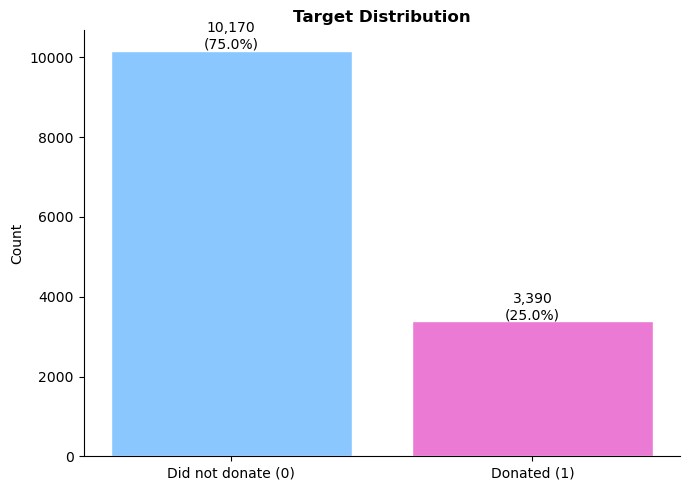

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))

target_counts = donors_train1['TARGET_B'].value_counts()
ax.bar(['Did not donate (0)', 'Donated (1)'], target_counts, color=["#8BC7FF", "#EB7AD4"], edgecolor='white')
for i, v in enumerate(target_counts):
    ax.text(i, v + 50, f'{v:,}\n({v/len(donors_train1)*100:.1f}%)', ha='center', fontsize=10)
ax.set_title('Target Distribution', fontweight='bold')
ax.set_ylabel('Count')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

The distribution of the target variable, `TARGET_B`, revealed a clear class imbalance, with 75% of the observations corresponding to individuals who did not donate (0) and only 25% to those who donated (1). 


This imbalance is important for the modelling stage, since machine learning models may become biased toward the majority class. Therefore, accuracy alone would not be sufficient for model evaluation, making metrics such as the F1-score more appropriate. These metrics provide a better assessment of the model’s ability to correctly identify donor responses while balancing false positives and false negatives.

<b style="font-size:22px; color:#1f4e79;">
Barplots and Histograms
</b>

The distribution of each variable in the dataset was analysed through two complementary visualizations. Categorical variables were displayed as bar plots of category frequencies, allowing the inspection of the dominant categories and the overall balance between groups. Numerical variables were displayed as histograms, highlighting the overall shape of each distribution, identifying skewness, and revealing the presence of extreme values.

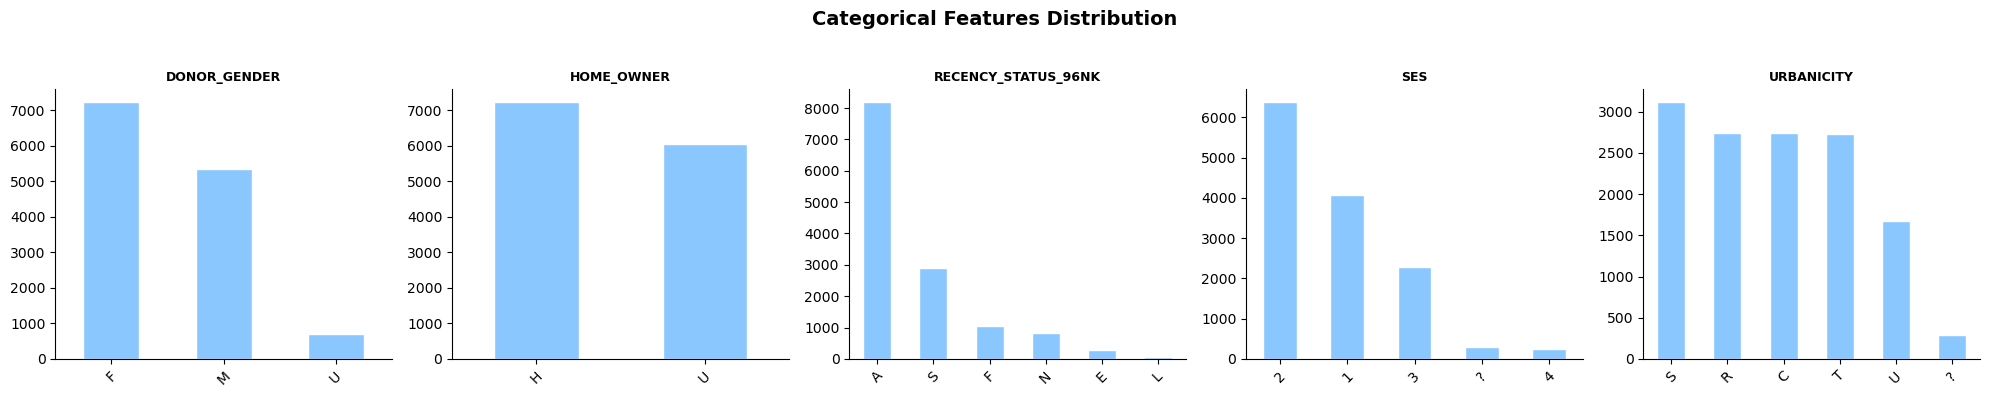

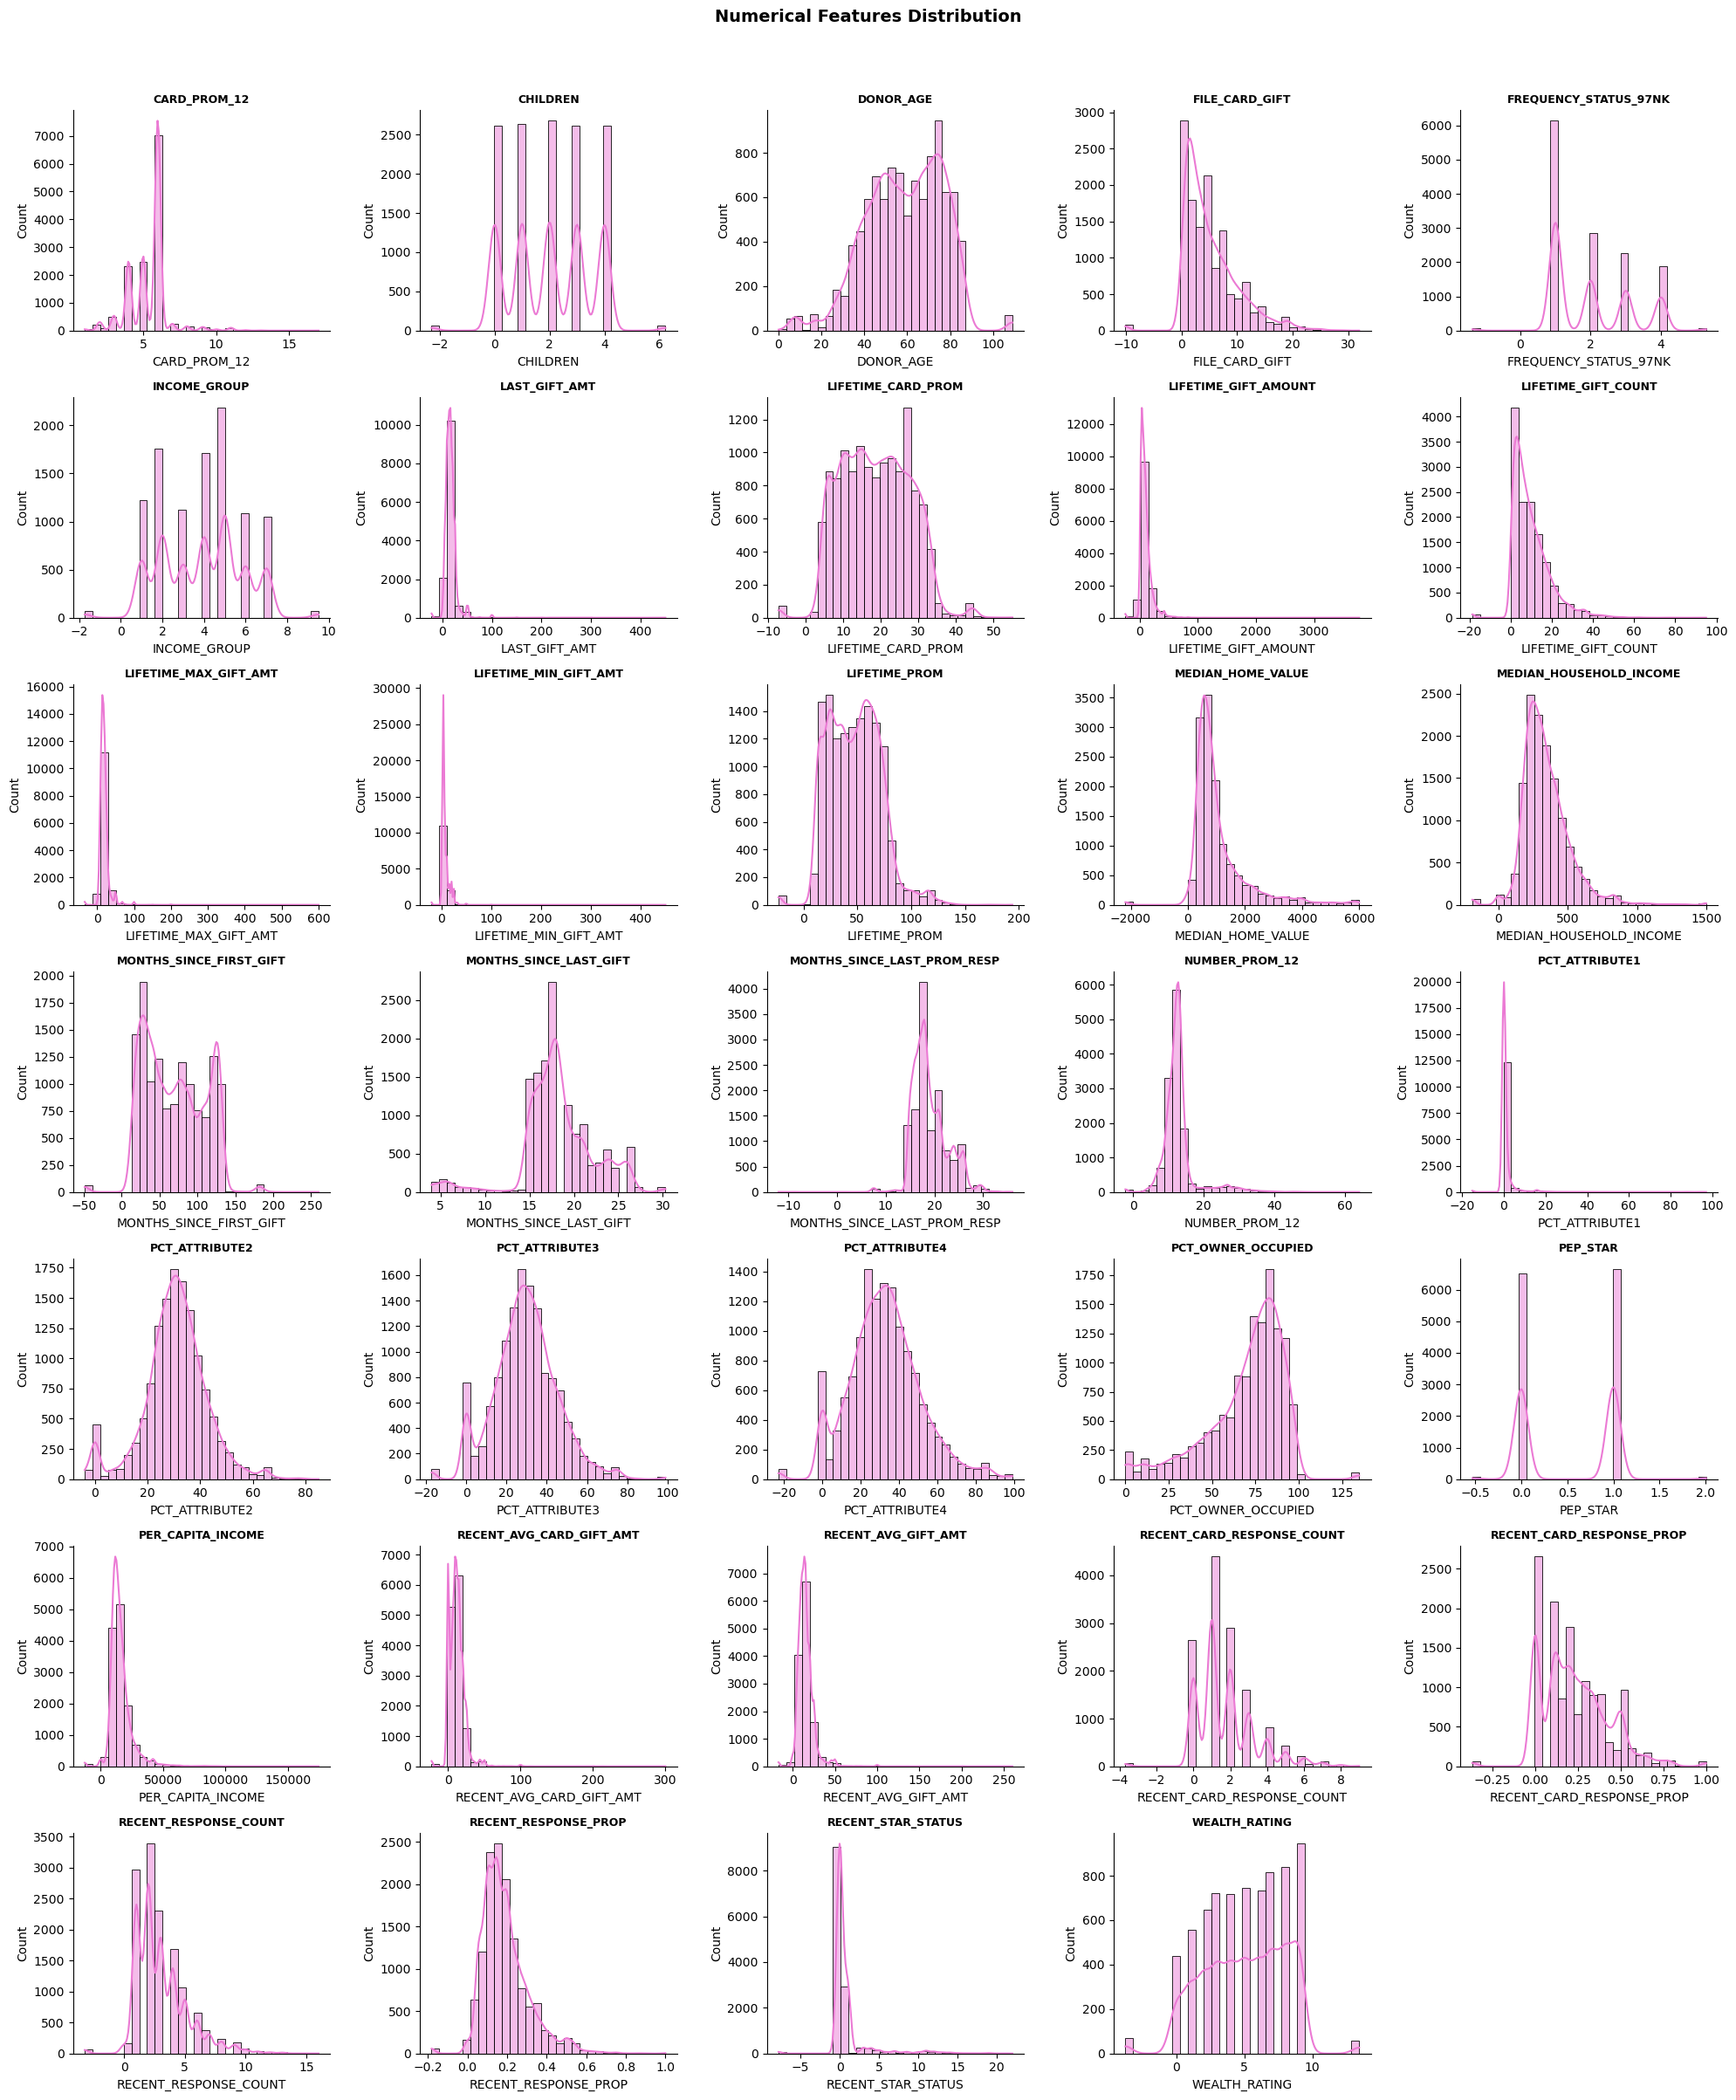

In [19]:
cat_cols = ['DONOR_GENDER', 'HOME_OWNER', 'RECENCY_STATUS_96NK', 'SES', 'URBANICITY']

numeric_cols = donors_train1.select_dtypes(include='number').drop(columns='TARGET_B').columns


# Barplots for categorical variables
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    donors_train1[col].value_counts().plot(kind='bar', ax=axes[i], color='#8BC7FF', edgecolor='white')
    axes[i].set_title(col, fontsize=9, fontweight='bold')
    axes[i].spines[['top', 'right']].set_visible(False)
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('Categorical Features Distribution', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Histograms for all numerical variables
n_cols = 5
n_rows = -(-len(numeric_cols) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(donors_train1[col].dropna(), bins=30, color='#EB7AD4', ax=axes[i], kde=True)
    axes[i].set_title(col, fontsize=9, fontweight='bold')
    axes[i].spines[['top', 'right']].set_visible(False)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numerical Features Distribution', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

<b>Categorical Variables Distribution</b>

The analysis of the categorical variables revealed different levels of concentration across their categories. `DONOR_GENDER` shows a clear predominance of female donors, with a small number of unknown values (`U`) also present. `HOME_OWNER` is split between home owners (`H`) and unknown (`U`), with home owners forming the majority. `RECENCY_STATUS_96NK` is strongly dominated by category `A`, while the remaining statuses (`S`, `F`, `N`, `E`, `L`) account for considerably fewer observations. `SES` presents high values in category "2" following by category "1", suggesting that a large part od the donors belong to that demographic profile. `URBANICITY` present more balanced distributions across their main levels, although contain a small group of inconsistent values (`?`), reinforcing the data quality issues previously identified during the inspection of distinct values. These imbalances are important to keep in mind for the subsequent encoding decisions and for the choice of appropriate evaluation metrics during modelling.


<br>
<b>Numerical Variables Distribution</b>

The numerical variables analysis showed that most donation-related and income-related features present highly right-skewed distributions. Variables such as `LIFETIME_GIFT_AMOUNT`, `LAST_GIFT_AMT`, `LIFETIME_MAX_GIFT_AMT`, `LIFETIME_MIN_GIFT_AMT`, `RECENT_AVG_GIFT_AMT`, and `PER_CAPITA_INCOME` contain a large concentration of smaller values and a smaller number of extremely large observations, reflecting differences in donor contribution behavior and underlying socioeconomic conditions.

Variables such as `DONOR_AGE` and percentage-related attributes present more balanced and approximately bell-shaped distributions, although some extreme values are still observable. Other numerical variables with a small number of distinct values, such as `CHILDREN`, `PEP_STAR`, `INCOME_GROUP`, `WEALTH_RATING`, and `FREQUENCY_STATUS_97NK`, appear concentrated around a few specific levels, which is consistent with their discrete nature.

Additionally, some numerical variables contain unexpected decimal and negative values, visible as small bars outside the main distribution in features such as `CHILDREN`, `PEP_STAR`, `MEDIAN_HOME_VALUE`, `MEDIAN_HOUSEHOLD_INCOME`, and `PCT_ATTRIBUTE1`, reinforcing the presence of potential data quality issues previously identified during the inspection of distinct values.

Overall, the distributions suggest the presence of outliers and non-normality across several numerical variables, which may influence the preprocessing strategy and model selection.

<h4> <b style="font-size:22px; color:#1f4e79;">
Boxplots
</b> </h4>

An interactive box plot was created for each numerical variable, allowing a focused inspection of the median, interquartile range, whiskers, and the position of individual extreme values.

In [20]:
numerical_columns = [col for col in donors_train1.select_dtypes(include=['number']).columns
                     if col not in ['PEP_STAR', 'INCOME_GROUP', 'WEALTH_RATING', 'TARGET_B']]

fig = go.Figure()
buttons = []

for idx, column in enumerate(numerical_columns):

    fig.add_trace(go.Box(
        x=donors_train1[column],
        name=f'<i>{column}</i>',
        marker_color='#8BC7FF',
        visible=(idx == 0)
    ))

    buttons.append(
        {'method': 'update',
         'label': column,
         'args': [{'visible': [i == idx for i in range(len(numerical_columns))]},
                  {'title': f'Box Plot for <i>{column}</i>', 'showlegend': True}]}
    )

fig.update_layout(
    updatemenus=[{'type': 'dropdown', 'active': 0, 'buttons': buttons, 'x': 1, 'y': 1.15}],
    title=f'Box Plot for <i>{numerical_columns[0]}</i>',
    showlegend=True,
    yaxis=dict(showticklabels=False)
)

fig.show()

The boxplots revealed the presence of numerous outliers across several numerical variables, particularly in donation-related, income-related, and promotion-related features. Variables such as `LIFETIME_GIFT_AMOUNT`, `LIFETIME_MAX_GIFT_AMT`, `RECENT_AVG_GIFT_AMT`, `RECENT_AVG_CARD_GIFT_AMT`, and `LAST_GIFT_AMT` contain a significant number of extreme observations, indicating that while most donors contribute relatively small amounts, a smaller group contributes substantially larger donations.

Income-related variables, including `PER_CAPITA_INCOME`, `MEDIAN_HOME_VALUE`, and `MEDIAN_HOUSEHOLD_INCOME`, also present extreme values and strong right-skewed distributions. These patterns are expected in socioeconomic datasets, where a small proportion of individuals may belong to considerably higher income groups.

Additionally, promotion and response variables such as `NUMBER_PROM_12`, `LIFETIME_PROM`, `RECENT_RESPONSE_COUNT`, and `RECENT_CARD_RESPONSE_COUNT` exhibit outliers associated with donors who were contacted or responded significantly more frequently than the majority of the population.

Some variables also present unrealistic negative values and unexpected decimal values in features that should logically contain only positive integers, such as `CHILDREN`, `FREQUENCY_STATUS_97NK`, and `RECENT_STAR_STATUS`. These observations suggest potential data quality issues or previous preprocessing anomalies that will require further treatment.

Despite the large number of outliers identified, these observations may represent legitimate donor behavior rather than errors, and therefore should not be automatically removed. High donation amounts and high-income values can provide valuable predictive information and therefore should be treated carefully instead of being automatically removed.